<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-05/lab-019-ising-without-labels.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning in Classical and Quantum Physics
2026/2027 <br>
**Author:** Marcin Płodzień <br>
**Lab:** 019 <br>
<hr/>

# Lab 019 — The 2D Ising model without labels

We use the Monte Carlo configurations of the 2D Ising model produced in Lab 018 for lattice sizes $L=20, 30, 50$, and judge two unsupervised methods the way a physicist would judge any new method: against what is already known.

We therefore start from the known answer. Onsager and Yang solved the model exactly, and on finite lattices a physicist extracts $T_c$ from constructed observables, the Binder cumulant and the susceptibility, analysed by finite-size scaling. Then we give the spins, and nothing else, to principal component analysis (PCA), a linear method, implemented in JAX and cross-checked with scikit-learn, and ask what it finds and why. Next comes autoencoder anomaly detection: an autoencoder is trained on configurations from one well-understood region, deep in the ordered phase, and its reconstruction error is scanned over temperature. We ask where the error rises, how that point moves with $L$, and how it depends on the choice of training region. The last section compares each unsupervised signal with the known $T_c$ and with the constructed observables.

> In Google Colab, run Lab 018 first (it writes `data/ising_L*.npz`), or upload those files to `data/`. The notebook runs on the CPU (central processing unit); `jax`, `flax`, `optax` and `scikit-learn` are pre-installed in Colab, and the stored outputs were produced with scikit-learn 1.6.1.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"
import time, json
from functools import partial
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

import jax
import jax.numpy as jnp
import optax
from flax import nnx

import sklearn                                  # scikit-learn: the outputs below were produced with version 1.6.1
from sklearn.decomposition import PCA
print("JAX", jax.__version__, "| devices:", jax.devices(), "| scikit-learn", sklearn.__version__)
UJBlue, UJNavy, DSOrange, UJGray = "#005CA7", "#002B5C", "#D35A05", "#5A6270"
SPIN_CMAP = ListedColormap(["#FFFFFF", UJNavy])
import matplotlib as mpl
mpl.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 14, "axes.labelsize": 15, "axes.titlesize": 15,
                     "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 12,
                     "figure.titlesize": 16, "lines.linewidth": 2.0})          # figures shown in the notebook
# figures for the slides are drawn at their size on the slide (text width 5.5 in) with 10-12 pt text
SLIDE = {"font.size": 11, "axes.labelsize": 11, "axes.titlesize": 12, "xtick.labelsize": 10,
         "ytick.labelsize": 10, "legend.fontsize": 10, "figure.titlesize": 12,
         "lines.linewidth": 1.5, "lines.markersize": 4}
FIG, DATA = "../beamer/figures", "data"
os.makedirs(FIG, exist_ok=True)
NUMBERS = {}
savefig = lambda fig, name: fig.savefig(f"{FIG}/{name}", dpi=200, bbox_inches="tight")
TC = 2.0 / np.log(1.0 + np.sqrt(2.0))
L_LIST = [20, 30, 50]
size_colors = dict(zip(L_LIST, plt.cm.viridis(np.linspace(0.05, 0.85, len(L_LIST)))))

def load(L):
    d = np.load(f"{DATA}/ising_L{L}.npz")
    s = np.unpackbits(d["configs"], axis=-1, count=L).astype(np.int8) * 2 - 1      # (nT, n, L, L)
    order = np.argsort(d["T"])                                                     # ascending temperature
    return d["T"][order], s[order]

DATA_SETS = {L: load(L) for L in L_LIST}
T_GRID = DATA_SETS[20][0]
for L, (T, s) in DATA_SETS.items():
    print(f"L = {L:2d}: {s.shape[0]} temperatures x {s.shape[1]} configurations")

JAX 0.11.0 | devices: [CpuDevice(id=0)] | scikit-learn 1.6.1
L = 20: 37 temperatures x 256 configurations
L = 30: 37 temperatures x 256 configurations
L = 50: 37 temperatures x 256 configurations


Three configurations of the $50\times50$ lattice, one below, one at and one above $T_c$ (white and navy: $s_i=-1$ and $+1$). Below $T_c$ one sign dominates, at $T_c$ domains of all sizes coexist, and above $T_c$ the spins are almost uncorrelated.

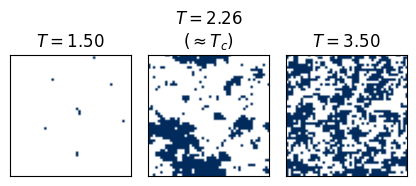

In [2]:
T50, s50 = DATA_SETS[50]
with mpl.rc_context(SLIDE):
    fig, ax = plt.subplots(1, 3, figsize=(4.3, 1.8))
    for a, Tv in zip(ax, [1.5, TC, 3.5]):
        i = int(np.argmin(abs(T50 - Tv)))
        a.imshow(s50[i, 0], cmap=SPIN_CMAP, vmin=-1, vmax=1); a.set_xticks([]); a.set_yticks([])
        for sp in a.spines.values(): sp.set_visible(True)
        a.set_title(f"$T = {T50[i]:.2f}$" + ("\n($\\approx T_c$)" if abs(T50[i] - TC) < 0.02 else ""))
    fig.tight_layout(); savefig(fig, "gen_ising_hook_samples.png"); plt.show()

<hr/>
## 1. Exact results and finite-size scaling

For the infinite lattice ($J=k_B=1$) the following is known exactly:
* Onsager (1944): $T_c = 2/\ln(1+\sqrt2) = 2.2692\ldots$, and the specific heat diverges logarithmically.
* Yang (1952): $M(T)=\left(1-\sinh^{-4}(2/T)\right)^{1/8}$ below $T_c$, so $M\sim (T_c-T)^{\beta}$ with $\beta=1/8$.
* The correlation length diverges as $\xi\sim|T-T_c|^{-\nu}$ with $\nu=1$, and the susceptibility as $\chi\sim|T-T_c|^{-\gamma}$ with $\gamma=7/4$.

On a finite lattice nothing diverges: when $\xi$ reaches $L$ the growth stops. Finite-size scaling turns this limitation into a tool. Near $T_c$ every observable depends on $T$ and $L$ only through $L/\xi$, i.e. through the scaling variable $t\,L^{1/\nu}$ with $t=(T-T_c)/T_c$:
$$
\langle|m|\rangle = L^{-\beta/\nu}\,\tilde m\!\left(tL^{1/\nu}\right),\qquad
\chi = L^{\gamma/\nu}\,\tilde\chi\!\left(tL^{1/\nu}\right),\qquad
U_4 = \tilde U\!\left(tL^{1/\nu}\right).
$$
Two consequences are used in practice. The **Binder cumulant** $U_4 = 1-\dfrac{\langle m^4\rangle}{3\langle m^2\rangle^2}$ is dimensionless, so at $t=0$ it takes the same value for every $L$: the curves for different $L$ cross at $T_c$. Its limits are $U_4\to 2/3$ in the ordered phase ($m=\pm M$ sharp) and $U_4\to0$ in the paramagnet ($m$ Gaussian, $\langle m^4\rangle = 3\langle m^2\rangle^2$). The **susceptibility peak** sits at $T_c(L)$ with $T_c(L)-T_c\propto L^{-1/\nu}$, and extrapolating to $L\to\infty$ gives $T_c$.

All these quantities are thermal averages over the Boltzmann distribution, $\langle O\rangle=\frac1Z\sum_{\mathbf s}O(\mathbf s)\,e^{-\beta H(\mathbf s)}$ with $Z=\sum_{\mathbf s}e^{-\beta H(\mathbf s)}$ and $\beta=1/T$. The data of Lab 018 contain, for every lattice size and temperature, $n=256$ configurations $\mathbf s^{(k)}$ sampled from this distribution, and every average is estimated by a sample mean over them. With $m_k=\frac1N\sum_is^{(k)}_i$ the magnetisation of sample $k$ and $\overline{x}=\frac1n\sum_kx_k$, the code below (functions `moments` and `blocked`) computes:

| observable | definition through $Z$ | estimator from $n$ samples (as in the code) |
|---|---|---|
| magnetisation | $\langle\lvert m\rvert\rangle=\frac1Z\sum_{\mathbf s}\lvert m(\mathbf s)\rvert e^{-\beta H}$ | $\overline{\lvert m\rvert}=\frac1n\sum_k\lvert m_k\rvert$ |
| susceptibility | $\chi=N\beta\big(\langle m^2\rangle-\langle\lvert m\rvert\rangle^2\big)$ | $N\beta\big(\overline{m^2}-\overline{\lvert m\rvert}^{\,2}\big)$ |
| Binder cumulant | $U_4=1-\dfrac{\langle m^4\rangle}{3\langle m^2\rangle^2}$ | $1-\dfrac{\overline{m^4}}{3\,\overline{m^2}^{\,2}}$ |

On a finite lattice $\langle m\rangle=0$ by the symmetry $\mathbf s\to-\mathbf s$, so the susceptibility is built from $|m|$; the variance in $\chi$ is a population variance (division by $n$). The error bar of an observable comes from $B=8$ blocks of consecutive columns of the data (groups of chains): the observable $O_b$ is computed on each block, and the error is $\sigma_B/\sqrt{B-1}$, with $\sigma_B$ the population standard deviation of the $O_b$.

Both observables were *constructed*: we had to know that $m$ is the order parameter. In the figure, look for the crossing of the Binder curves and for the drift of the susceptibility peak towards $T_c$ as $L$ grows.

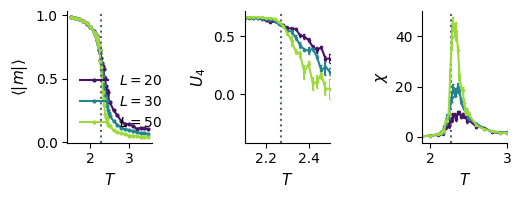

chi peak positions: {20: np.float64(2.38), 30: np.float64(2.36), 50: np.float64(2.3)}


In [3]:
def moments(x):
    # x: (nT, n) samples of a scalar order parameter -> U4, chi-like variance, mean |x|
    x2, x4 = (x**2).mean(1), (x**4).mean(1)
    return 1 - x4 / (3 * x2**2), x2 - np.abs(x).mean(1) ** 2, np.abs(x).mean(1)

def blocked(f, x, n_blocks=8):
    # mean and error of f(x) from n_blocks independent groups of samples (columns are grouped by chain in Lab 018)
    vals = np.stack([f(b) for b in np.array_split(x, n_blocks, axis=1)])
    return f(x), vals.std(0) / np.sqrt(n_blocks - 1)

M = {L: s.mean((-2, -1)).astype(np.float64) for L, (T, s) in DATA_SETS.items()}

with mpl.rc_context(SLIDE):
    fig, ax = plt.subplots(1, 3, figsize=(5.5, 2.1))
    chi_peak = {}
    for L in L_LIST:
        T = DATA_SETS[L][0]; N = L * L
        (U, U_err) = blocked(lambda x: moments(x)[0], M[L])
        (chi, chi_err) = blocked(lambda x: N * moments(x)[1], M[L])
        chi = chi / T; chi_err = chi_err / T
        ax[0].plot(T, np.abs(M[L]).mean(1), ".-", color=size_colors[L], label=f"$L={L}$")
        ax[1].errorbar(T, U, U_err, fmt=".-", color=size_colors[L], label=f"$L={L}$", ms=3, capsize=1)
        ax[2].errorbar(T, chi, chi_err, fmt=".-", color=size_colors[L], ms=3, capsize=1)
        chi_peak[L] = T[np.argmax(chi)]
    for a, lab in zip(ax, [r"$\langle|m|\rangle$", r"$U_4$", r"$\chi$"]):
        a.axvline(TC, color=UJGray, ls=":"); a.set_xlabel("$T$"); a.set_ylabel(lab)
    ax[1].set_xlim(2.1, 2.5); ax[0].legend(frameon=False, loc="lower left"); ax[2].set_xlim(1.9, 3.0)
    fig.tight_layout(); savefig(fig, "gen_ising_fss_observables.png"); plt.show()
print("chi peak positions:", chi_peak)

### 1.1 Binder crossings and susceptibility peaks

To turn the figure into numbers, we find for each pair of consecutive sizes where $U_4(L)$ and $U_4(L')$ cross (linear interpolation between grid points). For the susceptibility we fit $T_c(L) = T_c + a\,L^{-1/\nu}$ with the exact $\nu=1$; the peak position is refined by a parabola through the three highest points.

In [4]:
def crossing(T, y1, y2, lo=2.1, hi=2.5):
    d = y1 - y2; sel = (T >= lo) & (T <= hi)
    T, d = T[sel], d[sel]
    idx = np.where(np.sign(d[:-1]) != np.sign(d[1:]))[0]
    if len(idx) == 0: return np.nan
    i = idx[np.argmin(abs(T[idx] - TC))] if len(idx) > 1 else idx[0]
    return T[i] - d[i] * (T[i + 1] - T[i]) / (d[i + 1] - d[i])

def peak(T, y):
    i = int(np.clip(np.argmax(y), 1, len(y) - 2))
    c = np.polyfit(T[i - 1:i + 2], y[i - 1:i + 2], 2)
    return -c[1] / (2 * c[0])

U4 = {L: moments(M[L])[0] for L in L_LIST}
cross = {(L1, L2): crossing(T_GRID, U4[L1], U4[L2]) for L1, L2 in zip(L_LIST[:-1], L_LIST[1:])}
for k, v in cross.items(): print(f"U4 crossing {k}: T = {v:.4f}")
chi_T = np.array([peak(T_GRID, L * L * moments(M[L])[1] / T_GRID) for L in L_LIST])
A = np.vstack([np.ones(len(L_LIST)), 1.0 / np.array(L_LIST)]).T
tc_chi, a_chi = np.linalg.lstsq(A, chi_T, rcond=None)[0]
print("chi peaks T_c(L):", np.round(chi_T, 4), f"-> extrapolated T_c = {tc_chi:.4f}  (exact {TC:.4f})")
NUMBERS.update(fss_U4_crossings={f"{a}-{b}": round(float(v), 4) for (a, b), v in cross.items()},
               fss_chi_peaks=[round(float(x), 4) for x in chi_T], fss_tc_chi=round(float(tc_chi), 4))

U4 crossing (20, 30): T = 2.2495
U4 crossing (30, 50): T = 2.2784
chi peaks T_c(L): [2.3714 2.3616 2.3031] -> extrapolated T_c = 2.2694  (exact 2.2692)


<hr/>
## 2. PCA on raw spins

PCA (Lab 016) diagonalises the covariance matrix of the data. Here a data point is one configuration, a vector of $N=L^2$ spins; the data set contains all temperatures, and no temperature or label is given to PCA.

### 2.1 PCA implementation in JAX

We compute the decomposition with a singular value decomposition in JAX, for $L=30$, and look at three things: how much variance the first component carries, what its weights, the entries of the principal direction $\boldsymbol\lambda_1$, look like on the lattice, and how the projection $w^{(1)}=\boldsymbol\lambda_1^{\top}(\mathbf s-\bar{\mathbf s})$ of a configuration $\mathbf s$ compares with the magnetisation.

fraction of the variance sigma_l^2 / sum sigma^2 of the first 5 components: [0.373  0.0141 0.0133 0.013  0.0124]
correlation between |w^(1)| and |m| over all configurations: 0.999960
entries of sqrt(N) lambda_1: mean 1.0000, std 0.0096


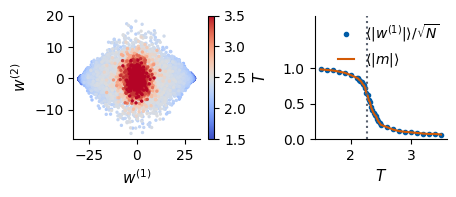

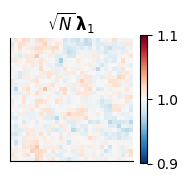

In [5]:
@jax.jit
def pca(X):
    mu = X.mean(0)
    _, S, Vt = jnp.linalg.svd(X - mu, full_matrices=False)
    return mu, S**2 / jnp.sum(S**2), Vt

L = 30
T, s = DATA_SETS[L]
X = jnp.asarray(s.reshape(-1, L * L), jnp.float32)
mu, var_ratio, Vt = pca(X)
z = np.asarray((X - mu) @ Vt[:2].T).reshape(len(T), -1, 2)
v1 = np.asarray(Vt[0]) * np.sign(np.asarray(Vt[0]).sum())
print("fraction of the variance sigma_l^2 / sum sigma^2 of the first 5 components:", np.round(np.asarray(var_ratio[:5]), 4))
corr = np.corrcoef(np.abs(z[..., 0]).ravel(), np.abs(M[L]).ravel())[0, 1]
print(f"correlation between |w^(1)| and |m| over all configurations: {corr:.6f}")
print(f"entries of sqrt(N) lambda_1: mean {np.mean(v1 * L):.4f}, std {np.std(v1 * L):.4f}")
NUMBERS.update(pca_L=L, pca_var1=round(float(var_ratio[0]), 4), pca_var2=round(float(var_ratio[1]), 4),
               pca_corr_pc1_m=round(float(corr), 6), pca_v1_std=round(float(np.std(v1 * L)), 4))

with mpl.rc_context(SLIDE):
    fig, ax = plt.subplots(1, 2, figsize=(4.7, 2.1), gridspec_kw=dict(width_ratios=[1.2, 1]))
    sc = ax[0].scatter(z[..., 0].ravel(), z[..., 1].ravel(), c=np.repeat(T, z.shape[1]), cmap="coolwarm", s=2)
    plt.colorbar(sc, ax=ax[0], label="$T$"); ax[0].set_xlabel("$w^{(1)}$"); ax[0].set_ylabel("$w^{(2)}$")
    ax[1].plot(T, np.abs(z[..., 0]).mean(1) / L, "o", ms=3, color=UJBlue, label=r"$\langle|w^{(1)}|\rangle/\sqrt{N}$")
    ax[1].plot(T, np.abs(M[L]).mean(1), "-", color=DSOrange, label=r"$\langle|m|\rangle$")
    ax[1].axvline(TC, color=UJGray, ls=":"); ax[1].set_xlabel("$T$"); ax[1].set_ylim(0, 1.75); ax[1].set_yticks([0, 0.5, 1.0])
    ax[1].legend(frameon=False, loc="upper right", handlelength=1.2, borderaxespad=0.1)
    fig.tight_layout(); savefig(fig, "gen_ising_pca.png"); plt.show()

with mpl.rc_context(SLIDE):
    fig, ax = plt.subplots(figsize=(2.1, 1.9))
    im = ax.imshow((v1 * L).reshape(L, L), cmap="RdBu_r", vmin=0.9, vmax=1.1); plt.colorbar(im, ax=ax)
    ax.set_title(r"$\sqrt{N}\,\boldsymbol{\lambda}_1$"); ax.set_xticks([]); ax.set_yticks([])
    fig.tight_layout(); savefig(fig, "gen_ising_v1.png"); plt.show()

The first component carries far more variance than all others, its weights are uniform over the lattice, and its projection is almost perfectly correlated with $|m|$. The reason is simple. Below $T_c$ the spins are strongly correlated, $\langle s_is_j\rangle\approx M^2$ for all pairs; the covariance matrix has a large uniform block, and its leading eigenvector is the uniform vector $\boldsymbol\lambda_1\approx(1,\dots,1)/\sqrt N$. The projection is then $w^{(1)}=\boldsymbol\lambda_1^{\top}(\mathbf s-\bar{\mathbf s})\approx\sqrt N\,(m-\bar m)$, where $\bar m$ is the magnetisation averaged over the whole data set. The correlation of 0.99996 between $|w^{(1)}|$ and $|m|$ shows that $\bar m$ is negligible here, so $w^{(1)}\approx\sqrt N\,m$.

PCA has therefore not discovered anything we could not have guessed: the Ising order parameter is *linear* in the spins, and a linear method finds linear structure. That is still useful, because the first principal component is an order-parameter **candidate** produced without prior knowledge, and its weights $\boldsymbol\lambda_1$ show *which pattern* orders. Lab 020 tests the same idea on a model with two different ordering patterns; Lab 021 on a model where the relevant variables are not linear in the spins.

Because $w^{(1)}\propto m$, every finite-size analysis of Section 1 can be repeated with $w^{(1)}$ instead of $m$ and gives nearly the same numbers:

In [6]:
z1 = {}
for L in L_LIST:
    T, s = DATA_SETS[L]
    Xl = jnp.asarray(s.reshape(-1, L * L), jnp.float32)
    mu_l, _, Vt_l = pca(Xl)
    z1[L] = np.asarray((Xl - mu_l) @ Vt_l[0]).reshape(len(T), -1) / L      # = m up to a sign
U4_pca = {L: moments(z1[L])[0] for L in L_LIST}
cross_pca = {(L1, L2): crossing(T_GRID, U4_pca[L1], U4_pca[L2]) for L1, L2 in zip(L_LIST[:-1], L_LIST[1:])}
for k in cross: print(f"crossing {k}:  U4(m) {cross[k]:.4f}   U4(w^(1)) {cross_pca[k]:.4f}")

crossing (20, 30):  U4(m) 2.2495   U4(w^(1)) 2.2495
crossing (30, 50):  U4(m) 2.2784   U4(w^(1)) 2.2773


The crossings from the first principal component reproduce those from $m$: for the first pair of sizes to all printed digits, for the second up to a difference in the third decimal.

### 2.2 PCA with scikit-learn

The same decomposition with scikit-learn: the estimator `PCA(n_components=5, svd_solver="full")` is fitted to the same $L=30$ configurations with `fit(X)`; it stores the mean configuration in `mean_`, the components as the rows of `components_` and their fractions of the variance in `explained_variance_ratio_`, and `transform(X)` returns the projections. With `svd_solver="full"` it performs a complete singular value decomposition (SVD) of the centred data, the same computation as our `pca`, so the fractions of variance must agree to float32 precision. The sign of a component is arbitrary in both programs, so components are compared through the absolute cosine of the angle between them. The first component is well separated from the rest of the spectrum and must agree; components 2–5 have almost equal variances, and a nearly degenerate eigenvalue leaves its eigenvector poorly defined, so for them only the variances are compared. The cell asserts the agreement and prints the correlation of the two projections on the first component.

In [7]:
L = 30
X30 = np.asarray(DATA_SETS[L][1].reshape(-1, L * L), np.float32)
sk_pca = PCA(n_components=5, svd_solver="full").fit(X30)
mu30, ratio30, Vt30 = pca(jnp.asarray(X30))
ratio30, Vt30 = np.asarray(ratio30), np.asarray(Vt30)
cos1 = abs(float(sk_pca.components_[0] @ Vt30[0]))
z1_sk = sk_pca.transform(X30)[:, 0]
corr_sk = abs(np.corrcoef(z1_sk, np.asarray((jnp.asarray(X30) - mu30) @ Vt30[0]))[0, 1])
print("fraction of variance, first 5 components:")
print("  JAX         ", np.round(ratio30[:5], 5))
print("  scikit-learn", np.round(sk_pca.explained_variance_ratio_, 5))
print(f"|cos| between the first components: {cos1:.8f} | correlation of the projections on PC 1: {corr_sk:.8f}")
assert np.allclose(sk_pca.explained_variance_ratio_, ratio30[:5], rtol=1e-3)
assert cos1 > 0.99999 and corr_sk > 0.99999
NUMBERS["pca_sklearn_var1"] = round(float(sk_pca.explained_variance_ratio_[0]), 4)

fraction of variance, first 5 components:
  JAX          [0.37303 0.01408 0.01333 0.01298 0.01245]
  scikit-learn [0.37303 0.01408 0.01333 0.01298 0.01245]
|cos| between the first components: 0.99999988 | correlation of the projections on PC 1: 1.00000000


<hr/>
## 3. Autoencoder anomaly detection

PCA found the order parameter because it is linear in the spins. A different unsupervised approach does not look for an order parameter at all (Kottmann, Huembeli, Lewenstein, Acín, Phys. Rev. Lett. **125**, 170603 (2020)): train an autoencoder only on configurations from a region we understand, and use its reconstruction error as an **anomaly score** everywhere else. Inside the training region the error is small; where the data stop looking like the training data, it rises.

The architecture is the same for every $L$: the $N$ spins enter a dense layer of 128 units with the rectified linear activation $\mathrm{ReLU}(u)=\max(0,u)$, then a latent layer of 8 numbers; the decoder mirrors this and ends with $\tanh$, so $\hat s_i\in[-1,1]$. The loss is $\frac1N\lVert\mathbf s-\hat{\mathbf s}\rVert^2$, minimised with Adam (adaptive moment estimation: gradient descent in which the step of every parameter is set by running averages of its gradient and of its squared gradient).

The model is built with Flax NNX, the current interface (`flax.nnx`) of the neural-network library Flax for JAX. A model is a Python object (`nnx.Module`) whose layers hold their parameters; `nnx.Optimizer` holds the optax state, `nnx.value_and_grad` differentiates a loss with respect to the model's parameters, and `nnx.jit` compiles the whole training step.

In [8]:
class DenseAE(nnx.Module):
    def __init__(self, n_in, latent=8, hidden=128, *, rngs):
        self.e1 = nnx.Linear(n_in, hidden, rngs=rngs); self.e2 = nnx.Linear(hidden, latent, rngs=rngs)
        self.d1 = nnx.Linear(latent, hidden, rngs=rngs); self.d2 = nnx.Linear(hidden, n_in, rngs=rngs)
    def encode(self, x):
        return self.e2(nnx.relu(self.e1(x)))
    def __call__(self, x):
        return jnp.tanh(self.d2(nnx.relu(self.d1(self.encode(x)))))

@nnx.jit
def train_step(model, opt, x):
    loss, grads = nnx.value_and_grad(lambda m: jnp.mean((m(x) - x) ** 2))(model)
    opt.update(model, grads)
    return loss

@nnx.jit
def recon_error(model, x):
    return jnp.mean((model(x) - x) ** 2, axis=-1)

def train_ae(X_train, epochs=200, batch=64, seed=0, lr=1e-3):
    model = DenseAE(X_train.shape[1], rngs=nnx.Rngs(seed))
    opt = nnx.Optimizer(model, optax.adam(lr), wrt=nnx.Param)
    X_train = jnp.asarray(X_train, jnp.float32); n = X_train.shape[0]
    key = jax.random.PRNGKey(seed); hist = []
    for ep in range(epochs):
        key, k = jax.random.split(key)
        perm = jax.random.permutation(k, n)
        for i in range(0, n - batch + 1, batch):
            loss = train_step(model, opt, X_train[perm[i:i + batch]])
        hist.append(float(loss))
    return model, hist

def error_vs_T(model, L):
    T, s = DATA_SETS[L]
    e = recon_error(model, jnp.asarray(s.reshape(-1, L * L), jnp.float32))
    return np.asarray(e).reshape(len(T), -1)

### 3.1 Training on the ordered phase

The well-understood region is the deep ordered phase, $T\le1.7$, where Yang's formula gives $M>0.97$ (the cell prints the value). We train one autoencoder per lattice size and three random seeds per size, and record the reconstruction error at every temperature.

To locate the rise of the error we need a definition that is robust to noise. The mean error rises like a smoothed step, and we fit
$$
\bar\varepsilon(T) = a + b\,\tanh\!\left(\frac{T-T^\ast}{\Delta}\right)
$$
on $1.9\le T\le 3.0$: the **signal temperature** $T^\ast(L)$ is the centre of the step, and $\Delta(L)$ its width. A fit uses all temperatures at once and is much less sensitive to noise than the position of the steepest slope between two grid points.

The susceptibility peak has a known finite-size law, $T_c(L)-T_c\propto L^{-1/\nu}$, so it can be extrapolated. The autoencoder signal is not a thermodynamic observable and has no derived law. We therefore watch how $T^\ast(L)$ and $\Delta(L)$ change with $L$, and compare the width with the finite-size rounding of the transition, $\propto L^{-1/\nu}=L^{-1}$.

In [9]:
T_TRAIN_MAX = 1.7
print(f"Yang: M(T = {T_TRAIN_MAX}) = {(1 - np.sinh(2 / T_TRAIN_MAX) ** -4) ** 0.125:.4f}")

from scipy.optimize import curve_fit

def step_fit(T, err, lo=1.9, hi=3.0):
    sel = (T >= lo) & (T <= hi)
    f = lambda t, a, b, t0, w: a + b * np.tanh((t - t0) / w)
    p0 = [0.5 * (err[sel].max() + err[sel].min()), 0.5 * (err[sel].max() - err[sel].min()), TC, 0.1]
    (a, b, t0, w), _ = curve_fit(f, T[sel], err[sel], p0=p0, maxfev=20000)
    return t0, abs(w)

SEEDS = [0, 1, 2]
ae_curves, T_star, W_star = {}, {}, {}
t0 = time.time()
for L in L_LIST:
    T, s = DATA_SETS[L]
    X_tr = s[T <= T_TRAIN_MAX].reshape(-1, L * L)
    curves = []
    for seed in SEEDS:
        model, hist = train_ae(X_tr, seed=seed)
        curves.append(error_vs_T(model, L).mean(1))
    ae_curves[L] = np.array(curves)
    fits = np.array([step_fit(T, c) for c in curves])
    T_star[L], W_star[L] = fits[:, 0], fits[:, 1]
    print(f"L = {L:2d}: train on {X_tr.shape[0]} configs, final loss {hist[-1]:.4f};  T* = {T_star[L].mean():.4f} +- {T_star[L].std():.1e},"
          f"  width Delta = {W_star[L].mean():.4f} +- {W_star[L].std():.1e} (mean +- std over {len(SEEDS)} seeds)   ({time.time() - t0:.0f} s)")
    if L == 30:                                                  # one example for the slides: input and reconstruction
        x_ex = jnp.asarray(s[np.argmin(abs(T - 2.0)), 0].reshape(1, -1), jnp.float32)
        for name, img in [("gen_ising_ae_in.png", x_ex), ("gen_ising_ae_out.png", model(x_ex))]:
            fig, ax = plt.subplots(figsize=(1.6, 1.6))
            ax.imshow(np.asarray(img).reshape(L, L), cmap="RdBu_r", vmin=-1, vmax=1); ax.axis("off")
            fig.savefig(f"{FIG}/{name}", dpi=150, bbox_inches="tight", pad_inches=0); plt.close(fig)

Yang: M(T = 1.7) = 0.9701


L = 20: train on 768 configs, final loss 0.0298;  T* = 2.3085 +- 1.1e-03,  width Delta = 0.2155 +- 7.0e-04 (mean +- std over 3 seeds)   (15 s)


L = 30: train on 768 configs, final loss 0.0376;  T* = 2.2767 +- 1.5e-03,  width Delta = 0.1512 +- 3.4e-04 (mean +- std over 3 seeds)   (31 s)


L = 50: train on 768 configs, final loss 0.0412;  T* = 2.2641 +- 4.9e-04,  width Delta = 0.1017 +- 3.0e-03 (mean +- std over 3 seeds)   (51 s)


The figure collects the result: the error curves for the three sizes (left), the centres $T^\ast(L)$ next to the susceptibility peaks $T_c(L)$ as functions of $1/L$ (middle), and the widths $\Delta(L)$ on logarithmic axes (right).

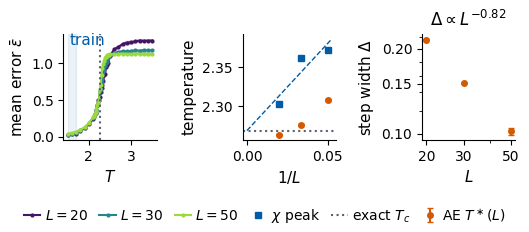

width of the step: {20: np.float64(0.215), 30: np.float64(0.151), 50: np.float64(0.102)};  power-law slope -0.82  (1/nu = 1 would give -1)
autoencoder T*(L) - T_c: {20: 0.039, 30: 0.008, 50: -0.005}
susceptibility peaks extrapolated with T_c(L) = T_c + a/L:  2.269   (exact 2.2692)


In [10]:
with mpl.rc_context(SLIDE):
    fig, ax = plt.subplots(1, 3, figsize=(5.5, 2.3))
    for L in L_LIST:
        T = DATA_SETS[L][0]
        c = ae_curves[L]
        ax[0].plot(T, c.mean(0), ".-", color=size_colors[L], label=f"$L={L}$")
        ax[0].fill_between(T, c.min(0), c.max(0), color=size_colors[L], alpha=0.25)
    ax[0].axvspan(T_GRID.min(), T_TRAIN_MAX, color=UJBlue, alpha=0.08)
    ax[0].text(1.55, 0.9 * ax[0].get_ylim()[1], "train", color=UJBlue)
    ax[0].axvline(TC, color=UJGray, ls=":"); ax[0].set_xlabel("$T$"); ax[0].set_ylabel(r"mean error $\bar\varepsilon$")

    invL = 1.0 / np.array(L_LIST)
    ts = np.array([T_star[L].mean() for L in L_LIST]); ts_err = np.array([T_star[L].std() for L in L_LIST])
    ax[1].errorbar(invL, ts, ts_err, fmt="o", color=DSOrange, label=r"AE $T^\ast(L)$", capsize=2)
    ax[1].plot(invL, chi_T, "s", color=UJBlue, label=r"$\chi$ peak")
    fit_chi = np.polyfit(invL, chi_T, 1)                    # T_c(L) = T_c + a/L  (nu = 1): a law for the susceptibility peak
    xx = np.linspace(0, invL.max() * 1.05, 50)
    ax[1].plot(xx, np.polyval(fit_chi, xx), "--", color=UJBlue, lw=1)
    ax[1].axhline(TC, color=UJGray, ls=":", label="exact $T_c$")
    ax[1].set_xlabel("$1/L$"); ax[1].set_ylabel("temperature")
    h0, l0 = ax[0].get_legend_handles_labels(); h1, l1 = ax[1].get_legend_handles_labels()
    fig.legend(h0 + h1, l0 + l1, frameon=False, loc="lower center", ncol=6, handlelength=1.2, columnspacing=0.8,
               handletextpad=0.3, borderaxespad=0.1)      # one legend row below the panels, clear of the data
    ws = np.array([W_star[L].mean() for L in L_LIST]); ws_err = np.array([W_star[L].std() for L in L_LIST])
    ax[2].errorbar(L_LIST, ws, ws_err, fmt="o", color=DSOrange, capsize=2)
    ax[2].set_xscale("log"); ax[2].set_yscale("log"); ax[2].set_xticks(L_LIST); ax[2].set_xticklabels([str(L) for L in L_LIST])
    ax[2].xaxis.set_minor_formatter(mpl.ticker.NullFormatter()); ax[2].yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
    ax[2].set_yticks([0.1, 0.15, 0.2]); ax[2].set_yticklabels(["0.10", "0.15", "0.20"])
    slope = np.polyfit(np.log(L_LIST), np.log(ws), 1)[0]
    ax[2].set_xlabel("$L$"); ax[2].set_ylabel("step width $\\Delta$"); ax[2].set_title(f"$\\Delta\\propto L^{{{slope:.2f}}}$")
    fig.tight_layout(rect=(0, 0.09, 1, 1)); savefig(fig, "gen_ising_ae_fss.png"); plt.show()
print(f"width of the step: {dict(zip(L_LIST, np.round(ws, 3)))};  power-law slope {slope:.2f}  (1/nu = 1 would give -1)")
NUMBERS.update(ae_width={str(L): round(float(w), 3) for L, w in zip(L_LIST, ws)}, ae_width_slope=round(float(slope), 2))
print("autoencoder T*(L) - T_c:", {L: round(float(T_star[L].mean() - TC), 3) for L in L_LIST})
print(f"susceptibility peaks extrapolated with T_c(L) = T_c + a/L:  {fit_chi[1]:.3f}   (exact {TC:.4f})")
NUMBERS.update(ae_T_star={str(L): [round(float(T_star[L].mean()), 3), round(float(T_star[L].std()), 3)] for L in L_LIST},
               chi_extrap_linear=round(float(fit_chi[1]), 3), ae_train_Tmax=T_TRAIN_MAX)

### 3.2 Dependence on the training region

A physical transition temperature cannot depend on our choice of training data. We repeat the experiment of Section 3.1 for every lattice
size with three training regimes:

* **ordered**: $T\le1.7$, deep in the ferromagnet (as above);
* **paramagnet**: $T\ge3.0$, deep in the disordered phase;
* **middle**: $2.20\le T\le2.34$, the temperatures around $T_c$.

For each regime and size we plot the mean reconstruction error
$\bar\varepsilon(T)=\langle\varepsilon(\boldsymbol s)\rangle_T$, with $\varepsilon(\boldsymbol s)=\frac1N\sum_i(s_i-\hat s_i)^2$ and the average over the
configurations sampled at temperature $T$, and the centre $T^\ast$ of the fitted step $a+b\tanh\big((T-T^\ast)/\Delta\big)$.

ordered, $T\leq1.7$             : T* = L=20: 2.308, L=30: 2.278, L=50: 2.264   (17 s)


paramagnet, $T\geq3.0$          : T* = L=20: 2.279, L=30: 2.253, L=50: 2.197   (50 s)


middle, $2.20\leq T\leq2.34$    : T* = L=20: 2.389, L=30: 2.363, L=50: 2.328   (94 s)


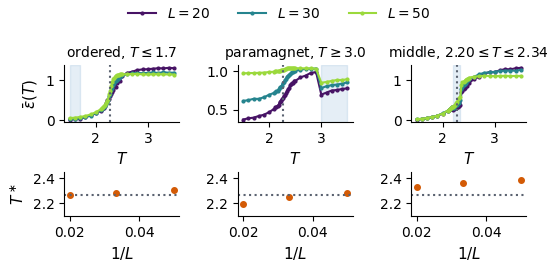

{
 "ordered, T<=1.7": {
  "20": 2.308,
  "30": 2.278,
  "50": 2.264
 },
 "paramagnet, T>=3.0": {
  "20": 2.279,
  "30": 2.253,
  "50": 2.197
 },
 "middle, 2.20<= T<=2.34": {
  "20": 2.389,
  "30": 2.363,
  "50": 2.328
 }
}


In [11]:
REGIMES = {"ordered, $T\\leq1.7$": lambda T: T <= 1.7,
           "paramagnet, $T\\geq3.0$": lambda T: T >= 3.0,
           "middle, $2.20\\leq T\\leq2.34$": lambda T: (T >= 2.195) & (T <= 2.345)}
regime_curves, regime_T = {}, {}
t0 = time.time()
for name, rule in REGIMES.items():
    for L in L_LIST:
        T, s = DATA_SETS[L]
        model, _ = train_ae(s[rule(T)].reshape(-1, L * L), seed=0)
        e = error_vs_T(model, L).mean(1)
        regime_curves[(name, L)] = e
        regime_T[(name, L)] = step_fit(T, e)[0]
    print(f"{name:32s}: T* = " + ", ".join(f"L={L}: {regime_T[(name, L)]:.3f}" for L in L_LIST) + f"   ({time.time() - t0:.0f} s)")

with mpl.rc_context(SLIDE):
    # top row: the error curves of the three training regimes; bottom row: the step centre T* against 1/L
    fig, axes = plt.subplots(2, len(REGIMES), figsize=(5.5, 2.7), gridspec_kw=dict(height_ratios=[1.3, 1]))
    for r, (name, rule) in enumerate(REGIMES.items()):
        a = axes[0, r]
        for L in L_LIST:
            T = DATA_SETS[L][0]; e = regime_curves[(name, L)]
            a.plot(T, e, ".-", color=size_colors[L], label=f"$L={L}$")
        T = DATA_SETS[L_LIST[0]][0]
        a.fill_between(T, 0, 1, where=rule(T), transform=a.get_xaxis_transform(), color=UJBlue, alpha=0.1)
        a.axvline(TC, color=UJGray, ls=":"); a.set_title(name, fontsize=10); a.set_xlabel("$T$")
        b = axes[1, r]
        b.plot(1.0 / np.array(L_LIST), [regime_T[(name, L)] for L in L_LIST], "o", color=DSOrange)
        b.axhline(TC, color=UJGray, ls=":"); b.set_ylim(2.1, 2.45); b.set_xlabel("$1/L$")
    axes[0, 0].set_ylabel(r"$\bar\varepsilon(T)$"); axes[1, 0].set_ylabel(r"$T^\ast$")
    fig.legend(*axes[0, 0].get_legend_handles_labels(), frameon=False, loc="upper center", ncol=3, borderaxespad=0.1)   # legend above the panels
    fig.tight_layout(rect=(0, 0, 1, 0.93), h_pad=0.3, w_pad=1.2); savefig(fig, "gen_ising_ae_regimes.png"); plt.show()
NUMBERS["ae_regime_T"] = {name.replace("$", "").replace("\\leq", "<=").replace("\\geq", ">="): {str(L): round(float(regime_T[(name, L)]), 3) for L in L_LIST}
                          for name in REGIMES}
print(json.dumps(NUMBERS["ae_regime_T"], indent=1))

### 3.3 Latent space and the magnetisation

The error tells us *where* the data change, but not *what* the autoencoder has learned. The 8 latent numbers of an autoencoder trained on all temperatures are compressed descriptions of a configuration, and a linear regression from the latent vector to $m$ tells us how much of the order parameter is stored there: a coefficient of determination $R^2$ close to 1 means that $m$ is a linear function of the latent numbers.

In [12]:
L = 30
T, s = DATA_SETS[L]
X_all = s.reshape(-1, L * L)
model_all, _ = train_ae(X_all, epochs=60, seed=0)
Z = np.asarray(model_all.encode(jnp.asarray(X_all, jnp.float32)))
m_abs = np.abs(M[L]).ravel(); m_sgn = M[L].ravel()
A_lat = np.hstack([Z, np.ones((len(Z), 1))])
coef = np.linalg.lstsq(A_lat, m_sgn, rcond=None)[0]
r2 = 1 - np.var(m_sgn - A_lat @ coef) / np.var(m_sgn)
print(f"linear readout of m from the 8 latent numbers: R^2 = {r2:.4f}")
NUMBERS["ae_latent_R2_m"] = round(float(r2), 4)

linear readout of m from the 8 latent numbers: R^2 = 0.9942


<hr/>
## 4. Summary

| method | what it was given | what it returned | relation to the known physics |
|---|---|---|---|
| Binder cumulant, $\chi$ | the order parameter $m$ (our knowledge) | $T_c$ with error bars | the standard, controlled route |
| PCA | spins only | $\boldsymbol\lambda_1$ uniform, $w^{(1)}\propto m$ | rediscovers the order parameter because it is linear in the spins |
| autoencoder, anomaly score | spins from one window of $T$ | the centre $T^\ast(L)$ and width $\Delta(L)$ of the step in the error | $T^\ast(L)\to T_c$ as $L$ grows; $\Delta$ shrinks roughly like the finite-size rounding $L^{-1/\nu}$ |

PCA gives an **order parameter**, after which the full finite-size machinery applies and the result is as good as the conventional one. The autoencoder gives a **signal**: the place where the data stop resembling the training data. Its centre approaches $T_c$ with $L$, its width shrinks with $L$, and it hardly depends on where in the ordered or disordered phase we trained. These are the properties we expect from a detector of the transition. With three lattice sizes the power law of the width is only indicative, and the signal has no derivation behind it: its value is in exploration, as a pointer to the region where a careful, conventional analysis is worth doing.

#### Exercises

1. Replace the mean reconstruction error by its **variance** over configurations at each $T$. Is the peak closer to $T_c$?
2. Train with latent dimension 1. What does the single latent number correlate with?
3. Repeat Section 3.1 with the training window $T\ge3.0$ for all sizes and compare $T^\ast(L)$ with the ordered-side result.

<hr/>
## References

* L. Onsager, Phys. Rev. **65**, 117 (1944), [doi:10.1103/PhysRev.65.117](https://doi.org/10.1103/PhysRev.65.117); C. N. Yang, Phys. Rev. **85**, 808 (1952), [doi:10.1103/PhysRev.85.808](https://doi.org/10.1103/PhysRev.85.808)
* K. Binder, *Finite size scaling analysis of Ising model block distribution functions*, Z. Phys. B **43**, 119 (1981), [doi:10.1007/BF01293604](https://doi.org/10.1007/BF01293604): the cumulant $U_4$.
* L. Wang, *Discovering phase transitions with unsupervised learning*, Phys. Rev. B **94**, 195105 (2016), [doi:10.1103/PhysRevB.94.195105](https://doi.org/10.1103/PhysRevB.94.195105): PCA on Ising configurations.
* S. J. Wetzel, *Unsupervised learning of phase transitions: from principal component analysis to variational autoencoders*, Phys. Rev. E **96**, 022140 (2017), [doi:10.1103/PhysRevE.96.022140](https://doi.org/10.1103/PhysRevE.96.022140)
* K. Kottmann, P. Huembeli, M. Lewenstein, A. Acín, *Unsupervised phase discovery with deep anomaly detection*, Phys. Rev. Lett. **125**, 170603 (2020), [arXiv:2003.09905](https://arxiv.org/abs/2003.09905)
* Textbook: M. E. J. Newman, G. T. Barkema, *Monte Carlo Methods in Statistical Physics*, Oxford University Press (1999), chapter on finite-size scaling.